In [21]:
import sys
from pathlib import Path

sys.path.append("..")

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline 

from src.clean import loadData, cleanData
from src.features import addFeatures, splitFeatures, scaleFeatures
from src.evaluate import plotPRCurve, createThresholdTable, bestf1Threshold

In [22]:
df = loadData("../data/raw/creditcard.csv")
df = cleanData(df)
df = addFeatures(df)

X,y = splitFeatures(df)

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=60)


def buildModels() -> dict:
    """returns dict of models"""

    models = {
        "logistic regression": Pipeline(
            [
                ("preprocess", scaleFeatures()),
                ("classifier", LogisticRegression(
                    class_weight = "balanced",
                    max_iter = 1000,
                    random_state = 60 
                ))
            ]
        ),
        "random forest": Pipeline(
            [
                ("preprocess",scaleFeatures()),
                ("classifier", RandomForestClassifier(
                    n_estimators=100, class_weight="balanced_subsample",
                    n_jobs=-1, random_state= 60
                ))
            ]
        )
    }

    return models

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=60)
oof_scores, test_scores, chosen = {},{},{}


for name,model in buildModels().items():
    # 1) out-of-fold probabilities on TRAIN data, used only to choose the threshold
    oof_scores[name] = cross_val_predict(model,X_train,y_train,cv=cv,method="predict_proba")[:,1]
    chosen[name] = bestf1Threshold(y_train,oof_scores[name])
    model.fit(X_train,y_train)
    test_scores[name] = model.predict_proba(X_test)[:,1]
    print(name," chosen threshold: ",round(chosen[name],3))




logistic regression  chosen threshold:  1.0
random forest  chosen threshold:  0.26


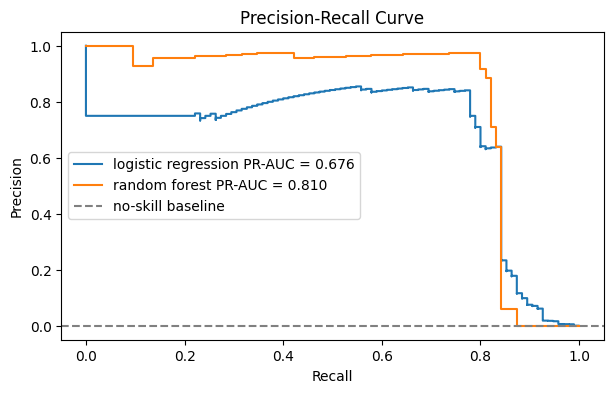

In [23]:
fig = plotPRCurve(test_scores,y_test)
Path("../reports").mkdir(exist_ok=True)
fig.savefig("../reports/pr_curve_3.png",dpi=150,bbox_inches="tight")

In [29]:
grid = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
print("Random Forest (out of fold, training data)")
print(createThresholdTable(y_train,oof_scores["random forest"], grid).round(3))
print("Logistic Regression (out of fold, training data)")
print(createThresholdTable(y_train,oof_scores["logistic regression"],grid).round(3))

Random Forest (out of fold, training data)
   Threshold  Precision  Recall     f1      tn   fp   fn   tp
0       0.05      0.632   0.854  0.727  226414  188   55  323
1       0.10      0.780   0.844  0.811  226512   90   59  319
2       0.20      0.891   0.825  0.857  226564   38   66  312
3       0.30      0.924   0.802  0.858  226577   25   75  303
4       0.40      0.939   0.780  0.853  226583   19   83  295
5       0.50      0.953   0.749  0.839  226588   14   95  283
6       0.60      0.957   0.712  0.816  226590   12  109  269
7       0.70      0.969   0.659  0.784  226594    8  129  249
8       0.80      0.977   0.550  0.704  226597    5  170  208
9       0.90      0.987   0.392  0.561  226600    2  230  148
Logistic Regression (out of fold, training data)
   Threshold  Precision  Recall     f1      tn     fp  fn   tp
0       0.05      0.004   0.984  0.008  137692  88910   6  372
1       0.10      0.007   0.952  0.015  178280  48322  18  360
2       0.20      0.016   0.939  0.03

In [30]:
for name,model in buildModels().items():
    print(name)
    print(createThresholdTable(y_test, test_scores[name],[0.5, chosen[name]]).round(3))

logistic regression
   Threshold  Precision  Recall     f1     tn    fp  fn  tp
0        0.5      0.062   0.916  0.117  55341  1310   8  87
1        1.0      0.804   0.779  0.791  56633    18  21  74
random forest
   Threshold  Precision  Recall     f1     tn  fp  fn  tp
0       0.50      0.972   0.726  0.831  56649   2  26  69
1       0.26      0.974   0.800  0.879  56649   2  19  76


In [21]:
print(chosen["logistic regression"])

0.9999989695996939


# Threshold analysis: summary

**Goal**: The default 0.5 cutoff is not necessarily the best decision threshold when only 0.17% of transactions are fraud. This note book finds out best f1 threshold

**Method**: Same cleaned data and features as `train.py`, stratified 80/20 split (`random_state=[42,58,60]`). The threshold is the cutoff with the highest F1 on **out-of-fold predictions from the training set only** (5-fold CV), so the test set (95 frauds) is used once, at the end.

**Results (test set)**

| Model               | Threshold | Precision | Recall | F1    | False alarms | Missed frauds |
|---------------------|-----------|-----------|--------|-------|--------------|---------------|
| Logistic Regression | 0.5       | 0.062     | 0.916  | 0.117 | 1,310        | 8             |
| Logistic Regression | 1.0       | 0.804     | 0.779  | 0.791 | 18           | 21            |
| Random Forest       | 0.5       | 0.972     | 0.726  | 0.831 | 2            | 26            |
| Random Forest       | 0.26      | 0.974     | 0.800  | 0.879 | 2            | 19            |


PR-AUC (threshold-free): Random Forest 0.810, Logistic Regression 0.676.

**Findings**
- Tuning removes almost all of Logistic Regression's false alarms (1,310 → 18). With `class_weight="balanced"` its probabilities are pushed towards 1, so its best cutoff is very high.
- For Random Forest, lowering the threshold catches more frauds at little extra cost. Out-of-fold F1 is nearly flat between 0.2 and 0.4, so the exact value is not special. The same pattern appeared on every seed I tried (42, 58, 60).
- Random Forest has the higher PR-AUC on every split tested. Both curves drop sharply at about 0.84 recall: the last frauds are hard to separate from normal transactions with these features.

**Limitations**
- With about 95 test frauds, differences of a few frauds are within noise. Different seeds moved Random Forest PR-AUC between 
0.81 and 0.87.
- F1 weights precision and recall equally. A real deployment would set the threshold from the cost of a missed fraud versus a false alert.
- Only three seeds were checked, not full repeated cross-validation.